Data Preprocessing

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA


iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [3]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
df_scaled = pd.DataFrame(
    X_scaled,
    columns=df.columns
)

df_scaled.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


KMeans Algorithm :KMeans is an unsupervised machine learning algorithm that divides data points into a predefined number of clusters.
The Iris dataset contains numerical features that can be used to calculate distances.

KMeans can group flowers with similar sepal and petal measurements.

In [8]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

kmeans_clusters = kmeans.fit_predict(X_scaled)
df['KMeans_Cluster'] = kmeans_clusters

df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),KMeans_Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,2
2,4.7,3.2,1.3,0.2,2
3,4.6,3.1,1.5,0.2,2
4,5.0,3.6,1.4,0.2,1


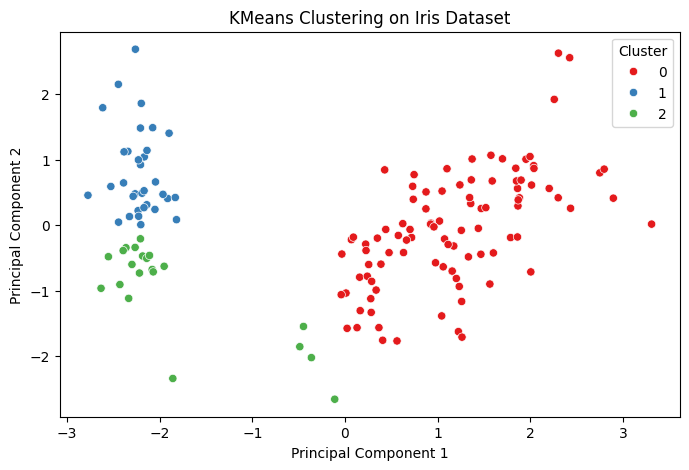

In [10]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['Cluster'] = kmeans_clusters


plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set1',

)

plt.title('KMeans Clustering on Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

Hierarchical Clustering is an unsupervised learning algorithm that groups similar data points into a hierarchy of clusters.It groups flowers based on similarities in their numerical measurements.
It does not require species labels.It helps us explore relationships between individual flowers and groups of flowers.

A dendrogram can provide insight into how clusters merge at different distances.

In [11]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hierarchical_clusters = hierarchical.fit_predict(X_scaled)

df['Hierarchical_Cluster'] = hierarchical_clusters
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),KMeans_Cluster,Hierarchical_Cluster
0,5.1,3.5,1.4,0.2,1,1
1,4.9,3.0,1.4,0.2,2,1
2,4.7,3.2,1.3,0.2,2,1
3,4.6,3.1,1.5,0.2,2,1
4,5.0,3.6,1.4,0.2,1,1
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,0,0
146,6.3,2.5,5.0,1.9,0,0
147,6.5,3.0,5.2,2.0,0,0
148,6.2,3.4,5.4,2.3,0,0


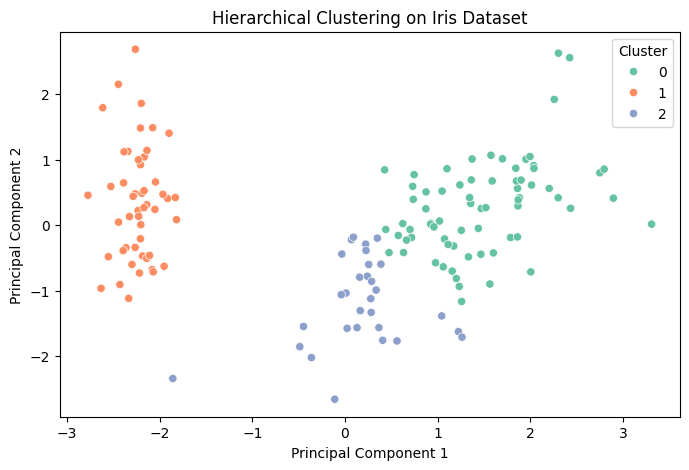

In [12]:
hierarchical_pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

hierarchical_pca_df['Cluster'] = hierarchical_clusters

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=hierarchical_pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set2',

)

plt.title('Hierarchical Clustering on Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()